<a href="https://colab.research.google.com/github/kuzeynalcakar/tcga-cancer-gmm-clustering/blob/main/hellingerdna.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q requests pandas tqdm scikit-learn seaborn matplotlib scipy


--- Downloading & parsing TCGA-LUAD ---


  TCGA-LUAD matrix: (50, 7469)

--- Downloading & parsing TCGA-LIHC ---


  TCGA-LIHC matrix: (50, 4108)

--- Downloading & parsing TCGA-PRAD ---


  TCGA-PRAD matrix: (48, 1325)

Combined sparse matrix shape (samples_total x genes): (148, 9756)
Fitting TruncatedSVD on combined data with n_components = 5
Combined embedding shape: (148, 5)

Fitting GMM for TCGA-LUAD, samples=50, dims=5
  chosen k (BIC) = 8

Fitting GMM for TCGA-LIHC, samples=50, dims=5
  chosen k (BIC) = 1

Fitting GMM for TCGA-PRAD, samples=48, dims=5
  chosen k (BIC) = 2
Pair TCGA-LUAD vs TCGA-LIHC: H=0.6823
Pair TCGA-LUAD vs TCGA-PRAD: H=0.8253
Pair TCGA-LIHC vs TCGA-PRAD: H=0.9138

Final Hellinger matrix:
            TCGA-LUAD  TCGA-LIHC  TCGA-PRAD
TCGA-LUAD   0.000000   0.682332   0.825291
TCGA-LIHC   0.682332   0.000000   0.913828
TCGA-PRAD   0.825291   0.913828   0.000000


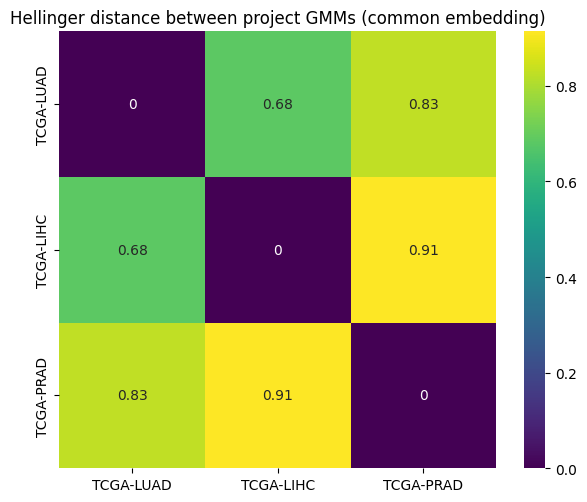

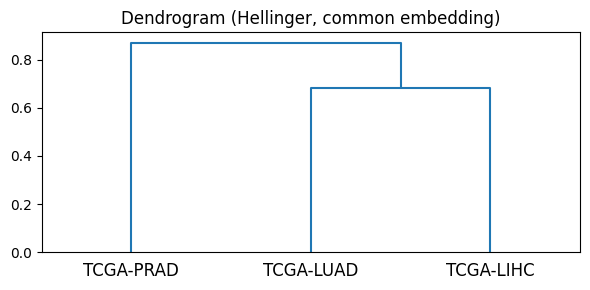

Saved outputs to dna_gmm_outputs


In [ ]:
# Colab-ready: syntax-clean ortak-embedding pipeline
# Önce: !pip install -q requests pandas tqdm scikit-learn seaborn matplotlib scipy

import os
import json
import time
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from tqdm import tqdm
import pandas as pd
import numpy as np
from scipy import sparse
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from scipy.special import logsumexp
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

# ---------- USER CONFIG ----------
PROJECTS = ["TCGA-LUAD", "TCGA-LIHC", "TCGA-PRAD"]  # değiştirilebilir
MAX_FILES_PER_PROJECT = 50    # test için küçük tut; tam analizde artır
DATA_DIR = "tcga_maf"
OUT_DIR = "dna_gmm_outputs"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

SVD_COMPONENTS = 5
GMM_MAX_COMPONENTS = 8
HELLINGER_SAMPLES = 2000
HELLINGER_RETRIES = [4000, 8000]
RANDOM_STATE = 42
# ---------------------------------

# HTTP session
session = requests.Session()
retries = Retry(total=5, backoff_factor=0.5, status_forcelist=[429,500,502,503,504])
session.mount("https://", HTTPAdapter(max_retries=retries))

def query_gdc_files(project, size=100, offset=0):
    url = "https://api.gdc.cancer.gov/files"
    filters = {
        "op": "and",
        "content": [
            {"op": "in", "content": {"field": "cases.project.project_id", "value": [project]}},
            {"op": "in", "content": {"field": "files.data_category", "value": ["Simple Nucleotide Variation"]}},
            {"op": "in", "content": {"field": "files.data_type", "value": ["Masked Somatic Mutation"]}}
        ]
    }
    params = {"filters": json.dumps(filters), "format": "JSON", "size": size, "from": offset}
    r = session.get(url, params=params, timeout=30)
    r.raise_for_status()
    return r.json()

def download_tcga_maf(project, max_files=MAX_FILES_PER_PROJECT):
    project_dir = os.path.join(DATA_DIR, project)
    os.makedirs(project_dir, exist_ok=True)
    files_info = []
    offset = 0
    page_size = 100
    while len(files_info) < max_files:
        info = query_gdc_files(project, size=page_size, offset=offset)
        hits = info.get("data", {}).get("hits", [])
        if not hits:
            break
        files_info.extend(hits)
        offset += len(hits)
        if len(hits) < page_size:
            break
    files_info = files_info[:max_files]
    downloaded = []
    for f in tqdm(files_info, desc=f"Downloading {project}", unit="file"):
        fname = f.get("file_name")
        fid = f.get("id")
        if not fname or not fid:
            continue
        out_path = os.path.join(project_dir, fname)
        if os.path.exists(out_path) and os.path.getsize(out_path) > 0:
            downloaded.append(out_path)
            continue
        download_url = f"https://api.gdc.cancer.gov/data/{fid}"
        try:
            with session.get(download_url, stream=True, timeout=90) as resp:
                resp.raise_for_status()
                with open(out_path, "wb") as h:
                    for chunk in resp.iter_content(chunk_size=16384):
                        if chunk:
                            h.write(chunk)
            downloaded.append(out_path)
        except Exception as e:
            print(f"  Warning: failed to download {fname}: {e}")
    return downloaded

def maf_to_sparse_df(maf_files):
    """Return pandas Sparse DataFrame (samples x genes) for the given files."""
    cts = []
    for file in maf_files:
        try:
            maf = pd.read_csv(file, sep='\t', comment='#', compression='infer',
                              low_memory=False, usecols=['Tumor_Sample_Barcode','Hugo_Symbol'])
        except Exception as e:
            print(f"  Warning: read failed {file}: {e}")
            continue
        maf = maf.dropna(subset=['Tumor_Sample_Barcode','Hugo_Symbol'])
        if maf.shape[0] == 0:
            continue
        ct = pd.crosstab(maf['Tumor_Sample_Barcode'], maf['Hugo_Symbol'])
        ct[ct > 1] = 1
        cts.append(ct)
    if not cts:
        return None
    genes = sorted(set().union(*(ct.columns for ct in cts)))
    rows = []
    row_index = []
    for ct in cts:
        ct2 = ct.reindex(columns=genes, fill_value=0)
        rows.append(sparse.csr_matrix(ct2.values))
        row_index.extend(list(ct2.index))
    big = sparse.vstack(rows, format='csr')
    df = pd.DataFrame.sparse.from_spmatrix(big, index=row_index, columns=genes)
    if df.index.duplicated().any():
        df = df.groupby(df.index).max()
    return df.astype(pd.SparseDtype("int", 0))

# ---------- Download + per-project sparse DF ----------
project_sparse = {}
for proj in PROJECTS:
    print(f"\n--- Downloading & parsing {proj} ---")
    try:
        files = download_tcga_maf(proj, max_files=MAX_FILES_PER_PROJECT)
    except Exception as e:
        print(f"  ERROR downloading {proj}: {e}")
        files = []
    if not files:
        print(" No files for", proj)
        continue
    df = maf_to_sparse_df(files)
    if df is None or df.shape[0] == 0:
        print(" Empty mutation matrix for", proj)
        continue
    project_sparse[proj] = df
    print(f"  {proj} matrix: {df.shape}")

if len(project_sparse) < 2:
    raise SystemExit("Yetersiz proje verisi — en az 2 proje gerekli.")

# ---------- BUILD COMBINED SPARSE MATRIX (same gene order) ----------
all_genes = sorted(set().union(*(set(df.columns) for df in project_sparse.values())))
sparse_list = []
row_project = []
row_index = []
for proj, df in project_sparse.items():
    df2 = df.reindex(columns=all_genes, fill_value=0)
    # Explicitly convert df2 to SparseDtype after reindex
    df2 = df2.astype(pd.SparseDtype("int", 0))
    X = df2.sparse.to_coo()
    sparse_list.append(X)
    row_project.extend([proj] * X.shape[0])
    row_index.extend(list(df2.index))

combined_sparse = sparse.vstack(sparse_list, format='csr')
assert combined_sparse.shape[0] == len(row_index) == len(row_project)

print("\nCombined sparse matrix shape (samples_total x genes):", combined_sparse.shape)

# ---------- COMMON SVD + scaling ----------
n_comp = min(SVD_COMPONENTS, combined_sparse.shape[1] - 1, combined_sparse.shape[0] - 1)
n_comp = max(1, n_comp)
svd = TruncatedSVD(n_components=n_comp, random_state=RANDOM_STATE)
print("Fitting TruncatedSVD on combined data with n_components =", n_comp)
combined_emb = svd.fit_transform(combined_sparse)
scaler = StandardScaler()
combined_emb_scaled = scaler.fit_transform(combined_emb)
print("Combined embedding shape:", combined_emb_scaled.shape)

# ---------- split embeddings back per-project ----------
project_embeddings = {}
start = 0
for proj, df in project_sparse.items():
    n = df.shape[0]
    project_embeddings[proj] = combined_emb_scaled[start:start + n, :]
    start += n

# ---------- Fit GMM per-project (in same common embedding space) ----------
project_gmms = {}
project_bics = {}
for proj, emb in project_embeddings.items():
    print(f"\nFitting GMM for {proj}, samples={emb.shape[0]}, dims={emb.shape[1]}")
    best_bic = np.inf
    best_gmm = None
    tried = []
    bics_list = []
    for k in range(1, GMM_MAX_COMPONENTS + 1):
        try:
            gm = GaussianMixture(n_components=k, covariance_type='full', n_init=5, random_state=RANDOM_STATE)
            gm.fit(emb)
            bic = gm.bic(emb)
            tried.append(k)
            bics_list.append(bic)
            if bic < best_bic:
                best_bic = bic
                best_gmm = gm
        except Exception as e:
            print(f"  GMM k={k} failed: {e}")
    if best_gmm is None:
        print(f"  GMM failed for all ks for {proj}")
        continue
    project_gmms[proj] = best_gmm
    project_bics[proj] = (tried, bics_list)
    print(f"  chosen k (BIC) = {best_gmm.n_components}")

if len(project_gmms) < 2:
    raise SystemExit("Yeterli GMM yok — en az 2 proje gerekir.")

# ---------- Robust pairwise Hellinger helpers ----------
def hellinger_mc(g1, g2, n_samples):
    n1 = max(1, n_samples // 2)
    n2 = max(1, n_samples - n1)
    X1, _ = g1.sample(n1)
    X2, _ = g2.sample(n2)
    X = np.vstack([X1, X2])
    logp = g1.score_samples(X)
    logq = g2.score_samples(X)
    logm = np.log(0.5) + logsumexp(np.vstack([logp, logq]), axis=0)
    log_sqrt = 0.5 * (logp + logq)
    with np.errstate(over='ignore', invalid='ignore'):
        w = np.exp(log_sqrt - logm)
    w = np.nan_to_num(w, nan=0.0, posinf=0.0, neginf=0.0)
    S = float(np.clip(np.mean(w), 0.0, 1.0))
    H = float(np.sqrt(max(0.0, 1.0 - S)))
    return H, S

def hellinger_grid(g1, g2, grid):
    logp = g1.score_samples(grid)
    logq = g2.score_samples(grid)
    logm = np.log(0.5) + logsumexp(np.vstack([logp, logq]), axis=0)
    log_sqrt = 0.5 * (logp + logq)
    with np.errstate(over='ignore', invalid='ignore'):
        w = np.exp(log_sqrt - logm)
    w = np.nan_to_num(w, nan=0.0, posinf=0.0, neginf=0.0)
    S = float(np.clip(np.mean(w), 0.0, 1.0))
    H = float(np.sqrt(max(0.0, 1.0 - S)))
    return H, S

def discrete_w_hellinger(g1, g2):
    wp = np.asarray(g1.weights_, dtype=float)
    wq = np.asarray(g2.weights_, dtype=float)
    if wp.sum() == 0:
        wp = np.ones_like(wp) / len(wp)
    if wq.sum() == 0:
        wq = np.ones_like(wq) / len(wq)
    L = max(len(wp), len(wq))
    wp2 = np.zeros(L)
    wq2 = np.zeros(L)
    wp2[:len(wp)] = wp
    wq2[:len(wq)] = wq
    wp2 = wp2 / wp2.sum()
    wq2 = wq2 / wq2.sum()
    H = np.sqrt(((np.sqrt(wp2) - np.sqrt(wq2)) ** 2).sum()) / np.sqrt(2)
    return float(H), (wp2, wq2)

# ---------- Compute pairwise robust Hellinger ----------
projects_done = list(project_gmms.keys())
m = len(projects_done)
Hmat = np.zeros((m, m))
Smat = np.zeros((m, m))
for i in range(m):
    for j in range(i, m):
        if i == j:
            Hmat[i, j] = 0.0
            Smat[i, j] = 1.0
            continue
        g1 = project_gmms[projects_done[i]]
        g2 = project_gmms[projects_done[j]]
        # try MC
        try:
            h, s = hellinger_mc(g1, g2, HELLINGER_SAMPLES)
        except Exception:
            h, s = np.nan, np.nan
        # retry if extreme or nan
        if (not np.isfinite(h)) or (h >= 0.995):
            for extra in HELLINGER_RETRIES:
                try:
                    h2, s2 = hellinger_mc(g1, g2, extra)
                    if np.isfinite(h2):
                        h, s = h2, s2
                        break
                except Exception:
                    continue
        # grid fallback
        if (not np.isfinite(h)) or (h >= 0.995):
            combined_grid = combined_emb_scaled
            if combined_grid.shape[0] > 5000:
                idx = np.random.RandomState(RANDOM_STATE).choice(combined_grid.shape[0], 5000, replace=False)
                grid = combined_grid[idx]
            else:
                grid = combined_grid
            try:
                hg, sg = hellinger_grid(g1, g2, grid)
                h, s = hg, sg
            except Exception:
                pass
        # discrete fallback
        if not np.isfinite(h):
            try:
                hw, _ = discrete_w_hellinger(g1, g2)
                h = hw
                s = np.nan
            except Exception:
                h = np.nan
                s = np.nan
        Hmat[i, j] = Hmat[j, i] = float(h)
        Smat[i, j] = Smat[j, i] = float(s) if np.isfinite(s) else np.nan
        print(f"Pair {projects_done[i]} vs {projects_done[j]}: H={Hmat[i,j]:.4f}")

dist_df = pd.DataFrame(Hmat, index=projects_done, columns=projects_done)
print("\nFinal Hellinger matrix:\n", dist_df)
dist_df.to_csv(os.path.join(OUT_DIR, "hellinger_distance_matrix.csv"))

# plot heatmap & dendrogram
plt.figure(figsize=(6,5))
sns.heatmap(dist_df.astype(float), annot=True, cmap="viridis", square=True)
plt.title("Hellinger distance between project GMMs (common embedding)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "hellinger_heatmap.png"), dpi=150)
plt.show()

max_finite = np.nanmax(Hmat[np.isfinite(Hmat)]) if np.any(np.isfinite(Hmat)) else 1.0
H_for_link = np.nan_to_num(Hmat, nan=max_finite)
if H_for_link.shape[0] > 1:
    condensed = squareform(H_for_link)
    Z = linkage(condensed, method='average')
    plt.figure(figsize=(6,3))
    dendrogram(Z, labels=projects_done)
    plt.title("Dendrogram (Hellinger, common embedding)")
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "hellinger_dendrogram.png"), dpi=150)
    plt.show()

summary = pd.DataFrame({
    "project": projects_done,
    "chosen_k": [project_gmms[p].n_components for p in projects_done],
    "n_samples": [project_embeddings[p].shape[0] for p in projects_done],
    "embedding_dims": [project_embeddings[p].shape[1] for p in projects_done],
})
summary.to_csv(os.path.join(OUT_DIR, "gmm_summary.csv"), index=False)
print("Saved outputs to", OUT_DIR)


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import os

# Check if svd and OUT_DIR are defined
if ('svd' not in locals() and 'svd' not in globals()) or ('OUT_DIR' not in locals() and 'OUT_DIR' not in globals()):
    print("Error: Required variables ('svd' and 'OUT_DIR') not found. Please ensure the main processing cell (cell_id: 4ryoNrqE7FNb) has been executed successfully before running this cell.")
else:
    # Get explained variance ratio
    explained_variance_ratio = svd.explained_variance_ratio_
    cumulative_explained_variance = np.cumsum(explained_variance_ratio)

    # Create a figure with two subplots
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Plot individual explained variance ratio
    axes[0].bar(range(1, len(explained_variance_ratio) + 1), explained_variance_ratio, color='skyblue')
    axes[0].set_xlabel('Principal Component')
    axes[0].set_ylabel('Explained Variance Ratio')
    axes[0].set_title('Individual Explained Variance Ratio')
    axes[0].set_xticks(range(1, len(explained_variance_ratio) + 1))
    axes[0].grid(axis='y', linestyle='--', alpha=0.7)

    # Plot cumulative explained variance ratio
    axes[1].plot(range(1, len(cumulative_explained_variance) + 1), cumulative_explained_variance, marker='o', linestyle='-', color='purple')
    axes[1].set_xlabel('Number of Principal Components')
    axes[1].set_ylabel('Cumulative Explained Variance Ratio')
    axes[1].set_title('Cumulative Explained Variance Ratio')
    axes[1].set_xticks(range(1, len(cumulative_explained_variance) + 1))
    axes[1].grid(axis='y', linestyle='--', alpha=0.7)

    plt.tight_layout()

    # Save the plot
    output_path = os.path.join(OUT_DIR, "svd_scree_plot.png")
    plt.savefig(output_path, dpi=150)

    plt.show()

    print(f"Scree plot saved to {output_path}")

Error: Required variables ('svd' and 'OUT_DIR') not found. Please ensure the main processing cell (cell_id: 4ryoNrqE7FNb) has been executed successfully before running this cell.
